## MiniProject IDS
### Network Intrusion Detection System using the UNSW-NB15 dataset 

## Part A
### The problem and the data

Every day, a large number of network requests and flows enter organizations. To be able to understand and react to the different types of network traffic, machine learning can be used. One way to do this is by creating an Intrusion Detection System (IDS) that can classify network flows as either malicious or benign. However, to train such a system, we need a large amount of labeled data, which can be difficult to obtain.

A machine-learning-based IDS can be used in companies and could assist Security Operations Centre (SOC) analysts and network administrators in detecting potential cyberattacks and malicious activity and potentially blocking harmful requests before they enter the system.

However, false alerts in an intrusion detection system can be costly, as security analysts monitoring these alerts need to investigate and determine whether they are actual attacks or not. Too many false alerts can lead to alert fatigue, where analysts become overwhelmed by the number of warnings. This can reduce the effectiveness of the system, as frequent false alerts can cause people to lose trust in it and potentially overlook real attacks. 


In [1]:
# Run in your terminal once: pip install -r requirements_ids.txt
from pathlib import Path
import warnings, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, recall_score, f1_score, precision_score,
                             average_precision_score, confusion_matrix)
from sklearn.base import clone
warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
START = time.perf_counter()
DATA_DIR = Path('data')
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
SAMPLE_SIZE = None  # Set to None to use all available rows
print('Data directory:', DATA_DIR.resolve())

Data directory: /Users/jimmy/Documents/Master/AI for cybersecurtiy/mini_project/data


### A1. Load and clean the CSV files

In [2]:
files = [DATA_DIR / "UNSW_NB15_training-set.csv",
         DATA_DIR / "UNSW_NB15_testing-set.csv"]

frames = []
for path in files:
    try:
        part = pd.read_csv(path, encoding="utf-8-sig", low_memory=False)
    except UnicodeDecodeError:
        part = pd.read_csv(path, encoding="latin1", low_memory=False)
    part.columns = part.columns.str.strip().str.lower()
    frames.append(part)

df = pd.concat(frames, ignore_index=True).drop(columns="id", errors="ignore")
df = df.replace([np.inf, -np.inf], np.nan).drop_duplicates().reset_index(drop=True)
df["label"] = pd.to_numeric(df["label"], errors="raise")
assert df["label"].isin([0, 1]).all(), "Unexpected target labels"
df["label"] = df["label"].astype(int)
df["attack_cat"] = df["attack_cat"].astype("string").str.strip().fillna("Unknown")

categorical = [c for c in ["proto", "service", "state"] if c in df]
for c in categorical:
    df[c] = df[c].astype("string").str.strip().fillna("Unknown")
for c in df.columns.difference(categorical + ["attack_cat", "label"]):
    df[c] = pd.to_numeric(df[c], errors="coerce")

# A small, stratified sample makes the presentation demo faster.
if SAMPLE_SIZE is not None and len(df) > SAMPLE_SIZE:
    df, _ = train_test_split(df, train_size=SAMPLE_SIZE,
                             stratify=df["label"], random_state=SEED)
    df = df.reset_index(drop=True)

print("Rows:", len(df))
print("Input features:", len(df.columns) - 2)
print("Class counts:\n", df["label"].value_counts().sort_index())
print("Class percentages:\n", (100 * df["label"].value_counts(normalize=True)).round(2))
print("Attack categories:\n", df["attack_cat"].value_counts())
print("Missing feature values:", df.drop(columns=["label", "attack_cat"]).isna().sum().sum())

Rows: 55945
Input features: 42
Class counts:
 label
0    34206
1    21739
Name: count, dtype: int64
Class percentages:
 label
0    61.14
1    38.86
Name: proportion, dtype: float64
Attack categories:
 attack_cat
Normal            34206
Exploits           7609
Fuzzers            4838
Generic            3657
Reconnaissance     2703
DoS                1718
Analysis            446
Shellcode           378
Backdoor            346
Worms                44
Name: count, dtype: Int64
Missing feature values: 0


### A2. Class balance and 60/20/20 split

Use 60% training, 20% validation, and 20% held-out testing, stratified by the binary label. Model choice is made on validation only. The test split is reserved until the final cell.

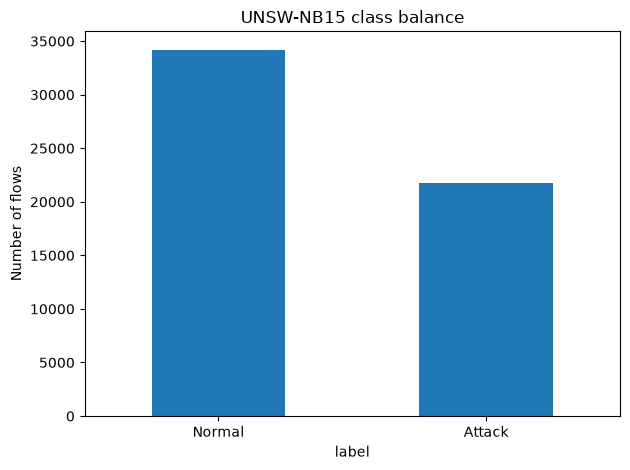

Train / validation / test: 33567 11189 11189


In [3]:
df["label"].map({0: "Normal", 1: "Attack"}).value_counts().reindex(["Normal", "Attack"]).plot.bar()
plt.title("UNSW-NB15 class balance")
plt.ylabel("Number of flows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

X = df.drop(columns=["label", "attack_cat"])
y = df["label"]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)
print("Train / validation / test:", len(X_train), len(X_val), len(X_test))

## Part B — Supervised models

In [4]:
numeric = X.select_dtypes(include="number").columns.tolist()
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric),
    ("cat", Pipeline([
        ("missing", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

# Candidate settings are compared on validation data in section B1.
model_templates = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess),
        ("scale", StandardScaler(with_mean=False)),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED))
    ]),
    "Decision Tree": Pipeline([
        ("prep", preprocess),
        ("clf", DecisionTreeClassifier(random_state=SEED))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(n_jobs=-1, random_state=SEED))
    ])
}

parameter_candidates = {
    "Logistic Regression": [{"clf__C": value} for value in [0.1, 1.0, 10.0]],
    "Decision Tree": [{"clf__max_depth": value} for value in [5, 10, None]],
    "Random Forest": [
        {"clf__n_estimators": n_estimators, "clf__max_depth": max_depth}
        for n_estimators in [100, 200]
        for max_depth in [10, None]
    ]
}

def scores(y_true, predicted, probability):
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y_true, predicted),
            "Macro-F1": f1_score(y_true, predicted, average="macro", zero_division=0),
            "Attack recall": recall_score(y_true, predicted, zero_division=0),
            "PR-AUC (AP)": average_precision_score(y_true, probability),
            "FAR": fp / (fp + tn) if fp + tn else 0.0}

majority = int(y_train.mode()[0])
def baseline(y_true):
    pred = np.full(len(y_true), majority)
    return scores(y_true, pred, pred.astype(float))

print("Majority class:", majority)
print("Training baseline accuracy:", round(baseline(y_train)["Accuracy"], 4))
print("Training baseline attack recall:", round(baseline(y_train)["Attack recall"], 4))

Majority class: 0
Training baseline accuracy: 0.6114
Training baseline attack recall: 0.0


### B1. Train models and compare on validation

All preprocessing is learned using **training data only**. Validation scores determine which model is selected. A higher macro-F1 is better.

In [5]:
validation = {"Majority baseline": baseline(y_val)}
models = {}
selected_settings = {}
tuning_rows = []

for name, template in model_templates.items():
    best_score = -1.0
    best_model = None
    best_metrics = None
    best_params = None

    for params in parameter_candidates[name]:
        candidate = clone(template).set_params(**params)
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_val)
        probability = candidate.predict_proba(X_val)[:, 1]
        metrics = scores(y_val, prediction, probability)
        tuning_rows.append({"Model": name, "Settings": str(params), **metrics})

        if metrics["Macro-F1"] > best_score:
            best_score = metrics["Macro-F1"]
            best_model = candidate
            best_metrics = metrics
            best_params = params

    models[name] = best_model
    validation[name] = best_metrics
    selected_settings[name] = best_params

print("Validation candidate settings:")
display(pd.DataFrame(tuning_rows).round(4))

validation_table = pd.DataFrame(validation).T.round(4)
print("Best validation result for each model:")
display(validation_table)
print("Selected settings:", selected_settings)

best_name = validation_table.drop(index="Majority baseline")["Macro-F1"].idxmax()
print("Selected model (validation macro-F1):", best_name)

Validation candidate settings:


,Model,Settings,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
0,Logistic Regression,{'clf__C': 0.1},0.8941,0.8873,0.8353,0.9492,0.0686
1,Logistic Regression,{'clf__C': 1.0},0.9014,0.8954,0.8510,0.9540,0.0665
2,Logistic Regression,{'clf__C': 10.0},0.9024,0.8965,0.8537,0.9554,0.0667
3,Decision Tree,{'clf__max_depth': 5},0.9029,0.8974,0.8641,0.9209,0.0725
4,Decision Tree,{'clf__max_depth': 10},0.9423,0.9386,0.8995,0.9658,0.0306
5,Decision Tree,{'clf__max_depth': None},0.9457,0.9428,0.9287,0.8926,0.0436
6,Random Forest,"{'clf__n_estimators': 100, 'clf__max_depth': 10}",0.9339,0.9300,0.8988,0.9765,0.0439
7,Random Forest,"{'clf__n_estimators': 100, 'clf__max_depth': N...",0.9597,0.9574,0.9363,0.9887,0.0254
8,Random Forest,"{'clf__n_estimators': 200, 'clf__max_depth': 10}",0.9348,0.9308,0.8967,0.9763,0.0411
9,Random Forest,"{'clf__n_estimators': 200, 'clf__max_depth': N...",0.9601,0.9578,0.9374,0.9897,0.0256


Best validation result for each model:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
Majority baseline,0.6114,0.3794,0.0000,0.3886,0.0000
Logistic Regression,0.9024,0.8965,0.8537,0.9554,0.0667
Decision Tree,0.9457,0.9428,0.9287,0.8926,0.0436
Random Forest,0.9601,0.9578,0.9374,0.9897,0.0256


Selected settings: {'Logistic Regression': {'clf__C': 10.0}, 'Decision Tree': {'clf__max_depth': None}, 'Random Forest': {'clf__n_estimators': 200, 'clf__max_depth': None}}
Selected model (validation macro-F1): Random Forest


### C1. Train black box on 5-10% labels

we investigate whether a Random Forest intrusion detector can learn effectively using only 10% of the training labels.

We compare three approaches:

1. Full supervised model: Random Forest trained using 100% of the training labels (from Part B).
2. Limited-label model: Random Forest trained using only 10% of the training labels.
3. Semi-supervised model: Random Forest trained using the 10% labelled data plus pseudo-labelled examples from the remaining 90%.

We evaluate the models using the same validation data and metrics from Part B.

In [6]:
# Keep only 10% of training records with their labels.
# The remaining 90% will be treated as unlabelled.
X_labeled, X_unlabeled, y_labeled, _ = train_test_split(
    X_train, y_train,train_size=0.10,
    stratify=y_train,random_state=SEED)

print("Total training records:", len(X_train))
print("Labelled records:", len(X_labeled))
print("Unlabelled records:", len(X_unlabeled))

# Create a fresh Random Forest 
rf_small = clone(models["Random Forest"])

# Train using only the 10% labelled records.
rf_small.fit(X_labeled, y_labeled)

# Evaluate on the same validation set from Part B.
pred_small = rf_small.predict(X_val)
prob_small = rf_small.predict_proba(X_val)[:, 1]

small_results = scores(y_val, pred_small, prob_small)

print("Random Forest trained with 10% labels:")
display(pd.DataFrame([small_results]).round(4))

Total training records: 33567
Labelled records: 3356
Unlabelled records: 30211
Random Forest trained with 10% labels:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
0,0.937,0.9333,0.9043,0.9767,0.0422


### C2. Semi-supervised learning using pseudo-labelling

The limited-label Random Forest predicts labels for the remaining training records. We compare confidence cutoffs of 0.80, 0.90, and 0.95, selecting the cutoff with the highest validation Macro-F1. Validation labels are used only to choose this cutoff; pseudo-labels are generated only for unlabelled training features.

In [7]:
# Predict probabilities for the unlabelled training records only.
probs = rf_small.predict_proba(X_unlabeled)
confidence = probs.max(axis=1)
pseudo_labels = rf_small.classes_[probs.argmax(axis=1)]

confidence_thresholds = [0.80, 0.90, 0.95]
semi_results_by_threshold = {}
semi_models_by_threshold = {}
pseudo_counts = {}

for threshold in confidence_thresholds:
    selected = confidence >= threshold
    X_combined = pd.concat([X_labeled, X_unlabeled.loc[selected]])
    y_combined = pd.concat([
        y_labeled,
        pd.Series(pseudo_labels[selected], index=X_unlabeled.index[selected])
    ])

    candidate = clone(models["Random Forest"])
    candidate.fit(X_combined, y_combined)
    prediction = candidate.predict(X_val)
    probability = candidate.predict_proba(X_val)[:, 1]

    semi_results_by_threshold[threshold] = scores(y_val, prediction, probability)
    semi_models_by_threshold[threshold] = candidate
    pseudo_counts[threshold] = int(selected.sum())

threshold_table = pd.DataFrame({
    threshold: semi_results_by_threshold[threshold]
    for threshold in confidence_thresholds
}).T
threshold_table.index.name = "Confidence threshold"
print("Validation results by pseudo-label confidence threshold:")
display(threshold_table.round(4))

best_threshold = max(
    confidence_thresholds,
    key=lambda threshold: semi_results_by_threshold[threshold]["Macro-F1"]
)
semi_results = semi_results_by_threshold[best_threshold]
rf_semi = semi_models_by_threshold[best_threshold]
print("Selected confidence threshold:", best_threshold)
print("Pseudo-labelled training records:", pseudo_counts[best_threshold])
print("Random Forest with selected pseudo-labelling threshold:")
display(pd.DataFrame([semi_results]).round(4))

Validation results by pseudo-label confidence threshold:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
Confidence threshold,,,,,
0.80,0.9272,0.9232,0.9000,0.9710,0.0555
0.90,0.9321,0.9283,0.9032,0.9739,0.0496
0.95,0.9316,0.9276,0.8949,0.9743,0.0450


Selected confidence threshold: 0.9
Pseudo-labelled training records: 20156
Random Forest with selected pseudo-labelling threshold:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
0,0.9321,0.9283,0.9032,0.9739,0.0496


### C3. Results and comparison

In [8]:
# Use the full-data Random Forest results from Part B.
comparison = pd.DataFrame({
    "RF - 100% labels": validation["Random Forest"],
    "RF - 10% labels": small_results,
    "RF - Pseudo-labelling": semi_results
}).T

print("Part C - Validation results:")
display(comparison.round(4))

gain = semi_results["Macro-F1"] - small_results["Macro-F1"]
print(f"\nMacro-F1 change with pseudo-labelling: {gain:+.6f}")

if abs(gain) < 0.001:
    print("Pseudo-labelling made no meaningful Macro-F1 change (< 0.001).")
elif gain > 0:
    print("Pseudo-labelling improved Macro-F1.")
else:
    print("Pseudo-labelling reduced Macro-F1.")

Part C - Validation results:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
RF - 100% labels,0.9601,0.9578,0.9374,0.9897,0.0256
RF - 10% labels,0.9370,0.9333,0.9043,0.9767,0.0422
RF - Pseudo-labelling,0.9321,0.9283,0.9032,0.9739,0.0496



Macro-F1 change with pseudo-labelling: -0.005059
Pseudo-labelling reduced Macro-F1.


## Final evaluation — held-out test

This cell reports test metrics only after all validation-based model and threshold choices are complete. Keep the evaluation at the end of the notebook as Parts D–G are added.

In [9]:
# Final held-out test evaluation for Parts A-C.
# NOTE Keep this cell last when adding later project parts; run it only after all validation-based choices.
final_models = {
    **models,
    "Random Forest - 10% labels": rf_small,
    "Random Forest - pseudo-labels": rf_semi
}
test_results = {"Majority baseline": baseline(y_test)}
for name, model in final_models.items():
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    test_results[name] = scores(y_test, prediction, probability)

test_table = pd.DataFrame(test_results).T.round(4)
print("Final held-out test results:")
display(test_table)
print("Validation-selected model:", best_name)
print("Selected model settings:", selected_settings[best_name])
print("Selected pseudo-label threshold:", best_threshold)

Final held-out test results:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
Majority baseline,0.6114,0.3794,0.0000,0.3886,0.0000
Logistic Regression,0.9017,0.8957,0.8514,0.9513,0.0664
Decision Tree,0.9500,0.9473,0.9338,0.9009,0.0398
Random Forest,0.9640,0.9619,0.9404,0.9906,0.0210
Random Forest - 10% labels,0.9354,0.9315,0.8977,0.9782,0.0406
Random Forest - pseudo-labels,0.9323,0.9285,0.9009,0.9749,0.0477


Validation-selected model: Random Forest
Selected model settings: {'clf__n_estimators': 200, 'clf__max_depth': None}
Selected pseudo-label threshold: 0.9


## Part D - Model explanations
In this part we'll investigate how the model makes its prediction by using SHAP and LIME.

### D1. Importance of features
We are using SHAP to identify which features contributes the most to the predictions.

SHAP shape: (100, 189, 2)
Attack SHAP shape: (100, 189)


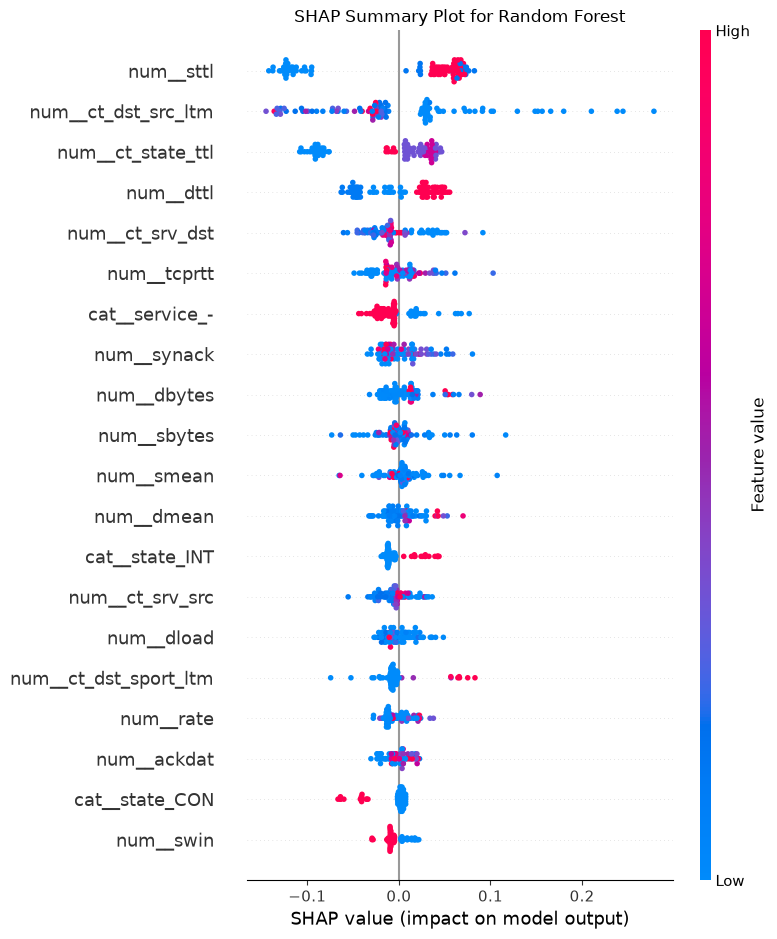

Top 10 features by mean absolute SHAP value:


,Feature,Mean |SHAP value|
0,num__sttl,0.073595
1,num__ct_dst_src_ltm,0.067753
2,num__ct_state_ttl,0.043669
3,num__dttl,0.035103
4,num__ct_srv_dst,0.023596
5,num__tcprtt,0.018357
6,cat__service_-,0.018241
7,num__synack,0.017572
8,num__dbytes,0.016499
9,num__sbytes,0.015440


In [14]:
import shap

# Use the trained Random Forest model from Part B for SHAP analysis
rf_pipeline = models["Random Forest"]

# Extract the classifier and preprocessor from the pipeline for SHAP analysis
rf_model = rf_pipeline.named_steps["clf"]
rf_preprocessor = rf_pipeline.named_steps["prep"]

X_shap_raw = X_val.sample(n=100, random_state=SEED)  # Use a sample for SHAP to speed up computation
X_shap = rf_preprocessor.transform(X_shap_raw)  # Apply the same preprocessing to the SHAP sample

if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()  # Convert sparse matrix to dense if necessary

# Get feature names after preprocessing
feature_names = rf_preprocessor.get_feature_names_out()

# Compute SHAP values for the Random Forest model
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap)

print("SHAP shape:", np.asarray(shap_values).shape)

# Select SHAP values for the attack class (1)
if isinstance(shap_values, list):
    attack_shap_values = shap_values[1]
else:
    attack_shap_values = shap_values[:, :, 1]

print("Attack SHAP shape:", np.asarray(attack_shap_values).shape)

# Generate the SHAP summary plot for the attack class
shap.summary_plot(
    attack_shap_values,
    X_shap,
    feature_names=feature_names,
    show=False
)

plt.title("SHAP Summary Plot for Random Forest")
plt.tight_layout()
plt.savefig(RESULTS / "shap_summary_plot.png", dpi=150, bbox_inches="tight")
plt.show()

# Display the top 10 features by mean absolute SHAP value
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean |SHAP value|": np.mean(np.abs(attack_shap_values), axis=0)
}).sort_values(by="Mean |SHAP value|", ascending=False)
print("Top 10 features by mean absolute SHAP value:")
display(shap_importance.head(10).reset_index(drop=True))

### D2. Local explanation using SHAP and LIME
We're using three validation flows to examine predictions. We're using a confident attack, a confident normal flow, and a misclassified flow.
Both SHAP and LIME will be used to explain the same three flows.

In [17]:
# Predictions from the random forest
val_prob = rf_pipeline.predict_proba(X_val)[:, 1]
val_pred = rf_pipeline.predict(X_val)

# Store the predictions and probabilities in a DataFrame for further analysis
val_results = pd.DataFrame({
    "True Label": y_val,
    "Predicted Label": val_pred,
    "Predicted Probability": val_prob
})

# Confidence in the predicted class
val_results["Confidence"] = np.where(val_results["Predicted Label"] == 1, val_results["Predicted Probability"], 1 - val_results["Predicted Probability"])

# Select one flow of each type
correct_attack = val_results[(val_results["True Label"] == 1) & (val_results["Predicted Label"] == 1)].nlargest(1, "Confidence")
correct_normal = val_results[(val_results["True Label"] == 0) & (val_results["Predicted Label"] == 0)].nlargest(1, "Confidence")
mistake = val_results[(val_results["True Label"] == 1) & (val_results["Predicted Label"] == 0)].nlargest(1, "Confidence")

selected_indices = {
    "Correct Attack": correct_attack.index[0],
    "Correct Normal": correct_normal.index[0],
    "Mistake": mistake.index[0]
}

selected_cases = val_results.loc[list(selected_indices.values())].copy()
selected_cases.insert(0, "Case", list(selected_indices.keys()))

display(selected_cases)

,Case,True Label,Predicted Label,Predicted Probability,Confidence
41023,Correct Attack,1,1,1.0,1.0
24056,Correct Normal,0,0,0.0,1.0
6877,Mistake,1,0,0.0,1.0
